# 4. Training Utilities / 2_Human_Gender_CNN — PyTorch (Nâng cao)
WIKI 64×64, 2 lớp. Adam(lr=1e-3), batch=128, max_epochs lớn + 4 tiện ích:

| Keras | PyTorch |
|---|---|
| ModelCheckpoint | `torch.save(model.state_dict(), ...pth)` khi val_loss tốt nhất |
| EarlyStopping(patience=5) | class `EarlyStopping` tự viết |
| ReduceLROnPlateau | `optim.lr_scheduler.ReduceLROnPlateau` |
| TensorBoard | `torch.utils.tensorboard.SummaryWriter` |

**Mốc Keras gốc:** Val accuracy ≈ 87.73% (loss ≈ 0.3237).

In [19]:
import os, random, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
try:
    from torchinfo import summary
except ImportError:                      # Kaggle có thể chưa cài torchinfo (khi tắt Internet)
    def summary(model, input_size=None, device=None):
        print(model)
        print("Tổng số tham số:", f"{sum(p.numel() for p in model.parameters()):,}")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
from torch.utils.tensorboard import SummaryWriter

Device: cuda


## Dữ liệu

In [20]:
# Kaggle: gắn dataset chứa 4 file .npy của WIKI (Add Input), code tự tìm đường dẫn
import glob
_p = glob.glob("/kaggle/input/**/64_64_11938_4098_train_x_onehot.npy", recursive=True)
assert _p, "Chưa thấy file WIKI: hãy Add Input -> dataset chứa 4 file .npy"
DATA_DIR = os.path.dirname(_p[0])
print("DATA_DIR =", DATA_DIR)

x_train = np.load(f"{DATA_DIR}/64_64_11938_4098_train_x_onehot.npy")
y_train = np.load(f"{DATA_DIR}/64_64_11938_4098_train_y_onehot.npy")
x_val   = np.load(f"{DATA_DIR}/64_64_5968_4098_val_x_onehot.npy")
y_val   = np.load(f"{DATA_DIR}/64_64_5968_4098_val_y_onehot.npy")
print("Gốc (NHWC):", x_train.shape, y_train.shape, x_val.shape, y_val.shape)

def prep_x(x):
    x = x.astype("float32")
    if x.ndim == 4:                       # (N, H, W, 1) -> (N, 1, H, W)
        x = x.transpose(0, 3, 1, 2)
    else:                                 # (N, H*W) hoặc (N, H, W)
        x = x.reshape(-1, 1, 64, 64)
    if x.max() > 1.0:                     # chuẩn hoá về [0, 1] nếu dữ liệu gốc là 0-255
        x = x / 255.0
    return np.ascontiguousarray(x)

x_train, x_val = prep_x(x_train), prep_x(x_val)
y_train = np.argmax(y_train, axis=1).astype("int64")   # one-hot -> nhãn số nguyên
y_val   = np.argmax(y_val,   axis=1).astype("int64")
print("PyTorch (NCHW):", x_train.shape, y_train.shape, x_val.shape, y_val.shape)
print("Phân bố nhãn train:", np.bincount(y_train))

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train)),
                          batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader   = DataLoader(TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val)),
                          batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
CLASS_NAMES = ["Nữ", "Nam"]   # 0 = Nữ, 1 = Nam

DATA_DIR = /kaggle/input/datasets/baygiokem10/wiki-gender
Gốc (NHWC): (11938, 64, 64, 1) (11938, 2) (5968, 64, 64, 1) (5968, 2)
PyTorch (NCHW): (11938, 1, 64, 64) (11938,) (5968, 1, 64, 64) (5968,)
Phân bố nhãn train: [2525 9413]


## Kiến trúc CNN

In [21]:
USE_BN = True    # lr=1e-3 + kiến trúc gốc (không BN) bị kẹt ở 78,85% trong PyTorch; đặt False để tái hiện   # False = đúng kiến trúc gốc (không BatchNorm); True = thêm BatchNorm2d sau mỗi Conv

def conv_block(in_c, out_c, n_conv, drop, bn=False):
    layers = []
    for i in range(n_conv):
        layers.append(nn.Conv2d(in_c if i == 0 else out_c, out_c, kernel_size=3, padding=1))
        if bn:
            layers.append(nn.BatchNorm2d(out_c))
        layers.append(nn.ReLU())
    layers += [nn.MaxPool2d(2), nn.Dropout(drop)]
    return layers

class GenderCNN(nn.Module):
    def __init__(self, num_classes=2, bn=False):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(1,   16,  2, 0.2, bn),   # 64 -> 32
            *conv_block(16,  32,  3, 0.2, bn),   # 32 -> 16
            *conv_block(32,  64,  3, 0.2, bn),   # 16 -> 8
            *conv_block(64,  128, 3, 0.2, bn),   # 8  -> 4
            *conv_block(128, 256, 3, 0.2, bn),   # 4  -> 2
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                    # 256*2*2 = 1024
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, num_classes),    # logits (softmax nằm trong CrossEntropyLoss)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def init_keras_like(m):
    """Keras mặc định: Glorot uniform cho trọng số, bias = 0. PyTorch mặc định khác, nên khởi tạo lại cho khớp."""
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_uniform_(m.weight)
        nn.init.zeros_(m.bias)

model = GenderCNN(bn=USE_BN)
model.apply(init_keras_like)
model = model.to(device)
summary(model, input_size=(1, 1, 64, 64), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
GenderCNN                                [1, 2]                    --
├─Sequential: 1-1                        [1, 256, 2, 2]            --
│    └─Conv2d: 2-1                       [1, 16, 64, 64]           160
│    └─BatchNorm2d: 2-2                  [1, 16, 64, 64]           32
│    └─ReLU: 2-3                         [1, 16, 64, 64]           --
│    └─Conv2d: 2-4                       [1, 16, 64, 64]           2,320
│    └─BatchNorm2d: 2-5                  [1, 16, 64, 64]           32
│    └─ReLU: 2-6                         [1, 16, 64, 64]           --
│    └─MaxPool2d: 2-7                    [1, 16, 32, 32]           --
│    └─Dropout: 2-8                      [1, 16, 32, 32]           --
│    └─Conv2d: 2-9                       [1, 32, 32, 32]           4,640
│    └─BatchNorm2d: 2-10                 [1, 32, 32, 32]           64
│    └─ReLU: 2-11                        [1, 32, 32, 32]           --
│    └─C

## Hàm huấn luyện / đánh giá + EarlyStopping

In [22]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()

@torch.no_grad()
def show_predictions(model, x_np, y_int, class_names, n=10):
    model.eval()
    idx = np.random.RandomState(SEED).choice(len(x_np), n, replace=False)
    xb = torch.tensor(x_np[idx], dtype=torch.float32).to(device)
    pred = model(xb).argmax(1).cpu().numpy()
    plt.figure(figsize=(2 * n, 2.6))
    for i, j in enumerate(idx):
        plt.subplot(1, n, i + 1)
        plt.imshow(x_np[j, 0], cmap="gray"); plt.axis("off")
        ok = pred[i] == y_int[j]
        plt.title(f"P:{class_names[pred[i]]}\nT:{class_names[y_int[j]]}", color="green" if ok else "red", fontsize=8)
    plt.show()


class EarlyStopping:
    """Tương đương keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)."""
    def __init__(self, patience=5, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.early_stop = None, 0, False
    def __call__(self, val_loss):
        if self.best is None or val_loss < self.best - self.min_delta:
            self.best, self.counter = val_loss, 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

## Huấn luyện với Checkpoint + EarlyStopping + ReduceLROnPlateau + TensorBoard

In [23]:
MAX_EPOCHS = 100
os.makedirs("checkpoints", exist_ok=True)
CKPT_PATH = "checkpoints/gender_best.pth"

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=5, min_lr=1e-4)
early_stopping = EarlyStopping(patience=5)
writer = SummaryWriter("./logs/gender")
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss = float("inf")

for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, val_loader, criterion, device)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)

    # TensorBoard
    writer.add_scalars("Loss", {"train": tr_loss, "val": va_loss}, epoch)
    writer.add_scalars("Accuracy", {"train": tr_acc, "val": va_acc}, epoch)
    writer.add_scalar("LearningRate", optimizer.param_groups[0]["lr"], epoch)

    # ModelCheckpoint (save_best_only, monitor=val_loss)
    saved = ""
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), CKPT_PATH)
        saved = " [saved]"

    # ReduceLROnPlateau
    scheduler.step(va_loss)

    print(f"Epoch {epoch:03d} - {time.time()-t0:.1f}s - loss: {tr_loss:.4f} - acc: {tr_acc:.4f} - val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f} - lr: {optimizer.param_groups[0]['lr']:.6f}{saved}")

    # EarlyStopping
    if early_stopping(va_loss):
        print(f"Early stopping tại epoch {epoch} (best val_loss = {early_stopping.best:.4f})")
        break
writer.close()

Epoch 001 - 7.0s - loss: 0.6603 - acc: 0.7767 - val_loss: 0.5160 - val_acc: 0.7885 - lr: 0.001000 [saved]
Epoch 002 - 7.0s - loss: 0.5302 - acc: 0.7878 - val_loss: 0.5168 - val_acc: 0.7885 - lr: 0.001000
Epoch 003 - 7.1s - loss: 0.5196 - acc: 0.7885 - val_loss: 0.5219 - val_acc: 0.7885 - lr: 0.001000
Epoch 004 - 7.4s - loss: 0.5154 - acc: 0.7885 - val_loss: 0.5136 - val_acc: 0.7885 - lr: 0.001000 [saved]
Epoch 005 - 7.6s - loss: 0.5089 - acc: 0.7885 - val_loss: 0.5187 - val_acc: 0.7885 - lr: 0.001000
Epoch 006 - 7.8s - loss: 0.4771 - acc: 0.7927 - val_loss: 0.5286 - val_acc: 0.7902 - lr: 0.001000
Epoch 007 - 7.8s - loss: 0.4531 - acc: 0.8084 - val_loss: 0.4563 - val_acc: 0.7988 - lr: 0.001000 [saved]
Epoch 008 - 7.6s - loss: 0.4180 - acc: 0.8314 - val_loss: 0.3983 - val_acc: 0.8398 - lr: 0.001000 [saved]
Epoch 009 - 7.4s - loss: 0.3937 - acc: 0.8432 - val_loss: 0.4693 - val_acc: 0.8018 - lr: 0.001000
Epoch 010 - 7.3s - loss: 0.3619 - acc: 0.8573 - val_loss: 0.4061 - val_acc: 0.8479 - l

## Tải lại trọng số tốt nhất & đánh giá

Best model - loss: 0.3060 | accuracy: 88.25%   (Keras gốc: ~0.3237 | ~87.73%)


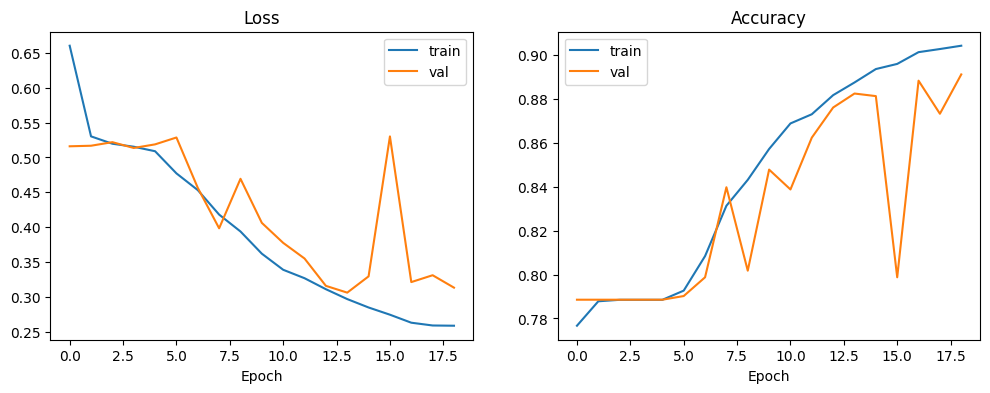

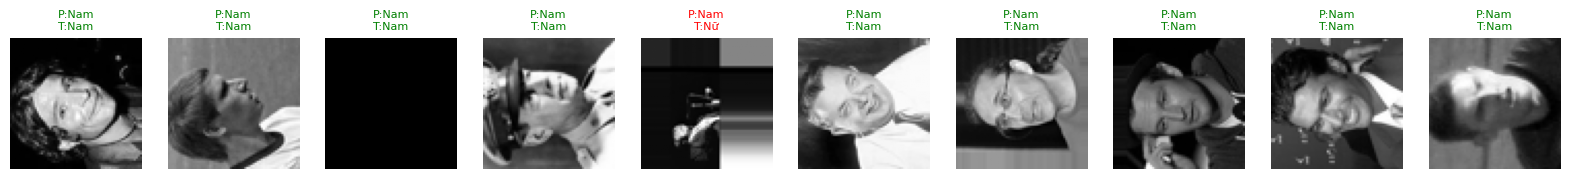

In [24]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
test_loss, test_acc = evaluate(model, val_loader, criterion, device)
print(f"Best model - loss: {test_loss:.4f} | accuracy: {test_acc*100:.2f}%   (Keras gốc: ~0.3237 | ~87.73%)")
plot_history(history)
show_predictions(model, x_val, y_val, CLASS_NAMES, n=10)

## TensorBoard (chụp màn hình thay `tfboard.PNG`)

In [ ]:
# TensorBoard: log đã ghi trong thư mục ./logs (tab Output sau khi Save Version).
# Tải thư mục logs về máy, chạy "tensorboard --logdir logs" rồi mở http://localhost:6006 để chụp màn hình.
print(os.listdir("logs"))

## Thư mục checkpoint (chụp màn hình thay `checkpoints.PNG`)

In [ ]:
import glob
for f in glob.glob("checkpoints/*"):
    print(f, f"{os.path.getsize(f)/1e6:.1f} MB")